In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/cifar-10/trainLabels.csv
/kaggle/input/competitions/cifar-10/sampleSubmission.csv
/kaggle/input/competitions/cifar-10/test.7z
/kaggle/input/competitions/cifar-10/train.7z


In [5]:
!pip install py7zr

In [6]:
import os
import py7zr

# Path to your train.7z file and destination folder
archive_path = "/kaggle/input/competitions/cifar-10/train.7z"
extract_dir = "./cifar10_data"

os.makedirs(extract_dir, exist_ok=True)

print(f"Extracting '{archive_path}' into '{extract_dir}'... (this takes about 1-2 minutes)")
with py7zr.SevenZipFile(archive_path, mode='r') as archive:
    archive.extractall(path=extract_dir)

print("Extraction complete!")

# Verify extracted images
extracted_train_path = os.path.join(extract_dir, "train")
if os.path.exists(extracted_train_path):
    num_files = len(os.listdir(extracted_train_path))
    print(f"Found {num_files} images in '{extracted_train_path}'")
else:
    print(f"Directory '{extracted_train_path}' not found, checking '{extract_dir}':")
    print(os.listdir(extract_dir)[:10])

Extracting '/kaggle/input/competitions/cifar-10/train.7z' into './cifar10_data'... (this takes about 1-2 minutes)
Extraction complete!
Found 50000 images in './cifar10_data/train'


In [7]:
import os
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [8]:
CSV_PATH = "/kaggle/input/competitions/cifar-10/trainLabels.csv"
TRAIN_IMG_DIR = "./cifar10_data/train"

CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}

class KaggleCIFAR10Dataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_id = str(row['id'])
        label_str = row['label']
        label = CLASS_TO_IDX[label_str]
        
        img_path = os.path.join(self.img_dir, f"{img_id}.png")
        image = Image.open(img_path).convert("RGB")
        
        if self.transform:
            image = self.transform(image)
        return image, label

img_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.2470, 0.2435, 0.2616])
])

print("Loading Kaggle CIFAR-10 images...")
full_cifar_dataset = KaggleCIFAR10Dataset(CSV_PATH, TRAIN_IMG_DIR, transform=img_transform)
print(f"Loaded {len(full_cifar_dataset)} labeled samples.")

# 80/20 train/test split on the labeled data
train_len = int(0.8 * len(full_cifar_dataset))
test_len = len(full_cifar_dataset) - train_len
train_set, test_set = random_split(
    full_cifar_dataset, [train_len, test_len],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=256, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

Loading Kaggle CIFAR-10 images...
Loaded 50000 labeled samples.


In [9]:
weights = models.ResNet18_Weights.DEFAULT
backbone = models.resnet18(weights=weights)
backbone.fc = nn.Identity()  # 512-D static features
backbone = backbone.to(device)
backbone.eval()

@torch.no_grad()
def extract_features(loader):
    feats_list, labels_list = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        feats = backbone(imgs)
        feats_list.append(feats.cpu())
        labels_list.append(labels)
    return torch.cat(feats_list, dim=0).to(device), torch.cat(labels_list, dim=0).to(device)

print("Extracting ResNet-18 embeddings...")
X_train, y_train = extract_features(train_loader)
X_test, y_test = extract_features(test_loader)
print(f"Embeddings ready -> Train: {X_train.shape}, Test: {X_test.shape}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 243MB/s]


Extracting ResNet-18 embeddings...
Embeddings ready -> Train: torch.Size([40000, 512]), Test: torch.Size([10000, 512])


In [10]:
class SmallNodeNet(nn.Module):
    def __init__(self, in_features, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

class TreeNeuron(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.model = SmallNodeNet(in_features)
        self.child_A = None
        self.child_B = None
        self.w_A = nn.Parameter(torch.tensor(0.0))
        self.w_B = nn.Parameter(torch.tensor(0.0))

    def compute_net(self, x):
        net = self.model(x)
        if self.child_A is not None:
            out_A = (self.child_A.compute_net(x) >= 0.0).float()
            net = net + torch.relu(self.w_A) * out_A
        if self.child_B is not None:
            out_B = (self.child_B.compute_net(x) >= 0.0).float()
            net = net - torch.relu(torch.abs(self.w_B)) * out_B
        return net

    def forward(self, x):
        return (self.compute_net(x) >= 0.0).float()

def count_tree_nodes(node):
    if node is None:
        return 0
    return 1 + count_tree_nodes(node.child_A) + count_tree_nodes(node.child_B)

def train_node_weighted(model, X, y, epochs=80, lr=0.005):
    num_pos = (y == 1).sum().float()
    num_neg = (y == 0).sum().float()

    if num_pos == 0 or num_neg == 0:
        return

    pos_weight = (num_neg / (num_pos + 1e-5)).clamp(min=1.0, max=50.0)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)

    y_f = y.float()
    for _ in range(epochs):
        optimizer.zero_grad()
        logits = model(X)
        loss = criterion(logits, y_f)
        loss.backward()
        optimizer.step()

def build_tree_node(X, y, depth=0, max_depth=12):
    node = TreeNeuron(in_features=X.shape[1]).to(device)
    train_node_weighted(node.model, X, y, epochs=80, lr=0.005)

    with torch.no_grad():
        base_logits = node.model(X)
        preds = (base_logits >= 0.0).long()
        errors = (preds != y)

    if not errors.any() or depth >= max_depth or len(X) <= 2:
        return node

    # C3: Actual 0, Desired 1; C4: Actual 1, Desired 0
    mask_c3 = (preds == 0) & (y == 1)
    mask_c4 = (preds == 1) & (y == 0)

    # Branch Child A for C3 errors (C2 is don't care)
    if mask_c3.any():
        mask_c2 = (preds == 1) & (y == 1)
        active_A = ~mask_c2

        X_A = X[active_A]
        y_A = torch.zeros(active_A.sum(), device=device, dtype=torch.long)
        c3_sub = mask_c3[active_A]
        y_A[c3_sub] = 1

        node.child_A = build_tree_node(X_A, y_A, depth=depth + 1, max_depth=max_depth)
        with torch.no_grad():
            neg_deficit = torch.abs(base_logits[mask_c3])
            node.w_A.data = torch.max(neg_deficit) + 2.0

    # Branch Child B for C4 errors (C1 is don't care)
    if mask_c4.any():
        mask_c1 = (preds == 0) & (y == 0)
        active_B = ~mask_c1

        X_B = X[active_B]
        y_B = torch.zeros(active_B.sum(), device=device, dtype=torch.long)
        c4_sub = mask_c4[active_B]
        y_B[c4_sub] = 1

        node.child_B = build_tree_node(X_B, y_B, depth=depth + 1, max_depth=max_depth)
        with torch.no_grad():
            pos_surplus = base_logits[mask_c4]
            node.w_B.data = torch.max(pos_surplus) + 2.0

    return node

In [11]:
class OneVsRestTreeNetwork:
    def __init__(self, num_classes=10, max_depth=12):
        self.num_classes = num_classes
        self.max_depth = max_depth
        self.trees = []

    def fit(self, X, y):
        self.trees = []
        for c in range(self.num_classes):
            print(f"--> Training Tree for Class {c} ({CLASSES[c]}) vs Rest...")
            y_binary = (y == c).long()
            tree = build_tree_node(X, y_binary, max_depth=self.max_depth)
            self.trees.append(tree)
            with torch.no_grad():
                acc = (tree(X) == y_binary).float().mean().item() * 100
                print(f"    Class {c} Binary Train Accuracy: {acc:.2f}% | Nodes: {count_tree_nodes(tree)}")

    def predict(self, X):
        scores = []
        with torch.no_grad():
            for tree in self.trees:
                raw_net = tree.compute_net(X)
                # Standardize outputs across trees to prevent w_A/w_B scale domination
                norm_net = (raw_net - raw_net.mean()) / (raw_net.std() + 1e-6)
                scores.append(norm_net.unsqueeze(1))
        all_scores = torch.cat(scores, dim=1)
        return torch.argmax(all_scores, dim=1)

    def total_nodes(self):
        return sum(count_tree_nodes(t) for t in self.trees)

print("\n--- Training Full OvR Tree Network on CIFAR-10 ---")
ovr_model = OneVsRestTreeNetwork(num_classes=10, max_depth=12)
ovr_model.fit(X_train, y_train)

with torch.no_grad():
    train_acc = (ovr_model.predict(X_train) == y_train).float().mean().item() * 100
    test_acc = (ovr_model.predict(X_test) == y_test).float().mean().item() * 100

print(f"\n==========================================")
print(f"Total Nodes Across 10 Trees: {ovr_model.total_nodes()}")
print(f"Final Multiclass Train Accuracy: {train_acc:.2f}%")
print(f"Final Multiclass Test Accuracy:  {test_acc:.2f}%")
print(f"==========================================\n")


--- Training Full OvR Tree Network on CIFAR-10 ---
--> Training Tree for Class 0 (airplane) vs Rest...
    Class 0 Binary Train Accuracy: 100.00% | Nodes: 26
--> Training Tree for Class 1 (automobile) vs Rest...
    Class 1 Binary Train Accuracy: 99.50% | Nodes: 51
--> Training Tree for Class 2 (bird) vs Rest...
    Class 2 Binary Train Accuracy: 99.69% | Nodes: 57
--> Training Tree for Class 3 (cat) vs Rest...
    Class 3 Binary Train Accuracy: 99.46% | Nodes: 81
--> Training Tree for Class 4 (deer) vs Rest...
    Class 4 Binary Train Accuracy: 99.55% | Nodes: 58
--> Training Tree for Class 5 (dog) vs Rest...
    Class 5 Binary Train Accuracy: 98.88% | Nodes: 65
--> Training Tree for Class 6 (frog) vs Rest...
    Class 6 Binary Train Accuracy: 99.72% | Nodes: 50
--> Training Tree for Class 7 (horse) vs Rest...
    Class 7 Binary Train Accuracy: 99.57% | Nodes: 55
--> Training Tree for Class 8 (ship) vs Rest...
    Class 8 Binary Train Accuracy: 99.72% | Nodes: 39
--> Training Tree fo

In [12]:
print("--- Running Double Descent Capacity Sweep (Airplane vs Rest) ---")
y_tr_c0 = (y_train == 0).long()
y_te_c0 = (y_test == 0).long()

depth_sweep = [1, 2, 4, 6, 8, 12, 16, 20, 25, 50]
tr_errs, te_errs, node_counts = [], [], []

for d in depth_sweep:
    t = build_tree_node(X_train, y_tr_c0, max_depth=d)
    with torch.no_grad():
        tr_e = 1.0 - (t(X_train) == y_tr_c0).float().mean().item()
        te_e = 1.0 - (t(X_test) == y_te_c0).float().mean().item()

    cnt = count_tree_nodes(t)
    tr_errs.append(tr_e)
    te_errs.append(te_e)
    node_counts.append(cnt)
    print(f"Depth: {d:2d} | Nodes: {cnt:4d} | Train Err: {tr_e*100:5.2f}% | Test Err: {te_e*100:5.2f}%")

--- Running Double Descent Capacity Sweep (Airplane vs Rest) ---
Depth:  1 | Nodes:    3 | Train Err:  3.82% | Test Err:  4.85%
Depth:  2 | Nodes:    7 | Train Err:  3.05% | Test Err:  5.82%
Depth:  4 | Nodes:   18 | Train Err:  3.64% | Test Err:  5.96%
Depth:  6 | Nodes:   38 | Train Err:  0.97% | Test Err:  6.01%
Depth:  8 | Nodes:   42 | Train Err:  0.39% | Test Err:  5.21%
Depth: 12 | Nodes:   44 | Train Err:  0.23% | Test Err:  5.71%
Depth: 16 | Nodes:   50 | Train Err:  0.25% | Test Err:  5.28%
Depth: 20 | Nodes:   51 | Train Err:  0.38% | Test Err:  5.71%
Depth: 25 | Nodes:   66 | Train Err:  0.36% | Test Err:  6.59%
Depth: 50 | Nodes:   93 | Train Err:  0.46% | Test Err:  5.63%


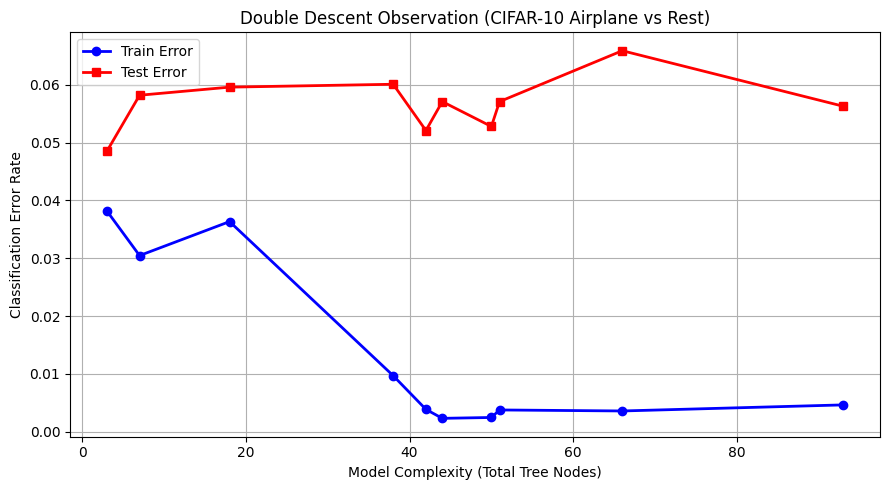

--> Saved sorted double descent plot as cifar10_double_descent_sorted.png


In [13]:
sorted_data = sorted(zip(node_counts, tr_errs, te_errs))

# 2. Unzip back into separate lists
sorted_nodes, sorted_train_err, sorted_test_err = zip(*sorted_data)

# 3. Plot the sorted data
plt.figure(figsize=(9, 5))
plt.plot(sorted_nodes, sorted_train_err, 'o-', label="Train Error", color="blue", linewidth=2)
plt.plot(sorted_nodes, sorted_test_err, 's-', label="Test Error", color="red", linewidth=2)

plt.xlabel("Model Complexity (Total Tree Nodes)")
plt.ylabel("Classification Error Rate")
plt.title("Double Descent Observation (CIFAR-10 Airplane vs Rest)")
plt.grid(True)
plt.legend()
plt.tight_layout()

# 4. Save and display
plt.savefig("cifar10_double_descent_sorted.png", dpi=300)
plt.show()
print("--> Saved sorted double descent plot as cifar10_double_descent_sorted.png")


--- Generating Receptive Field Saliency Map ---
--> Saved: cifar10_receptive_field.png


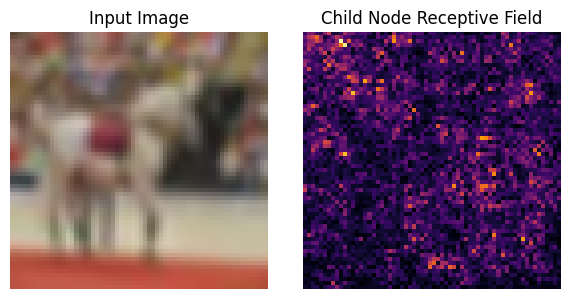

In [14]:
print("\n--- Generating Receptive Field Saliency Map ---")
target_tree = ovr_model.trees[0]
active_node = target_tree.child_A if target_tree.child_A is not None else target_tree

raw_img, _ = test_set[0]
raw_img_tensor = raw_img.unsqueeze(0).to(device)
raw_img_tensor.requires_grad = True

feat = backbone(raw_img_tensor)
logit = active_node.model(feat).squeeze()
logit.backward()

saliency, _ = torch.max(raw_img_tensor.grad.data.abs(), dim=1)
saliency = saliency.squeeze().cpu().numpy()
saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
raw_disp = raw_img.permute(1, 2, 0).numpy()
raw_disp = np.clip((raw_disp * [0.247, 0.243, 0.261] + [0.491, 0.482, 0.446]), 0, 1)

axes[0].imshow(raw_disp)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(saliency, cmap="inferno")
axes[1].set_title("Child Node Receptive Field")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("cifar10_receptive_field.png")
print("--> Saved: cifar10_receptive_field.png")

In [15]:
print("\n--- Pruning Sparse Nodes Across All 10 Trees ---")
def prune_sparse_nodes(node, X_eval, min_corrections=5):
    if node is None:
        return None
    node.child_A = prune_sparse_nodes(node.child_A, X_eval, min_corrections)
    node.child_B = prune_sparse_nodes(node.child_B, X_eval, min_corrections)

    if node.child_A is not None:
        with torch.no_grad():
            if (node.child_A(X_eval) >= 0.5).sum().item() < min_corrections:
                node.child_A = None
                node.w_A.data.fill_(0.0)

    if node.child_B is not None:
        with torch.no_grad():
            if (node.child_B(X_eval) >= 0.5).sum().item() < min_corrections:
                node.child_B = None
                node.w_B.data.fill_(0.0)
    return node

nodes_before = ovr_model.total_nodes()
for t in ovr_model.trees:
    prune_sparse_nodes(t, X_test, min_corrections=5)
nodes_after = ovr_model.total_nodes()

with torch.no_grad():
    pruned_test_acc = (ovr_model.predict(X_test) == y_test).float().mean().item() * 100

print(f"Total Nodes: {nodes_before} (Before) -> {nodes_after} (After Pruning)")
print(f"Final Pruned Multiclass Test Accuracy: {pruned_test_acc:.2f}%")
print("--> Complete pipeline finished.")


--- Pruning Sparse Nodes Across All 10 Trees ---
Total Nodes: 522 (Before) -> 452 (After Pruning)
Final Pruned Multiclass Test Accuracy: 67.92%
--> Complete pipeline finished.
